In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import cv2
import soundfile as sf

print("BirdSense environment is ready!")

BirdSense environment is ready!


In [4]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [5]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

audio_path = r"C:\Users\gavis\Desktop\BirdSense\data\raw\common_myna\XC1175438 - Common Myna - Acridotheres tristis.mp3"

audio, sr = librosa.load(audio_path, sr=None, mono=True)

print("Sample rate:", sr)
print("Number of samples:", len(audio))
print("Duration:", len(audio) / sr, "seconds")

Sample rate: 48000
Number of samples: 190703
Duration: 3.9729791666666667 seconds


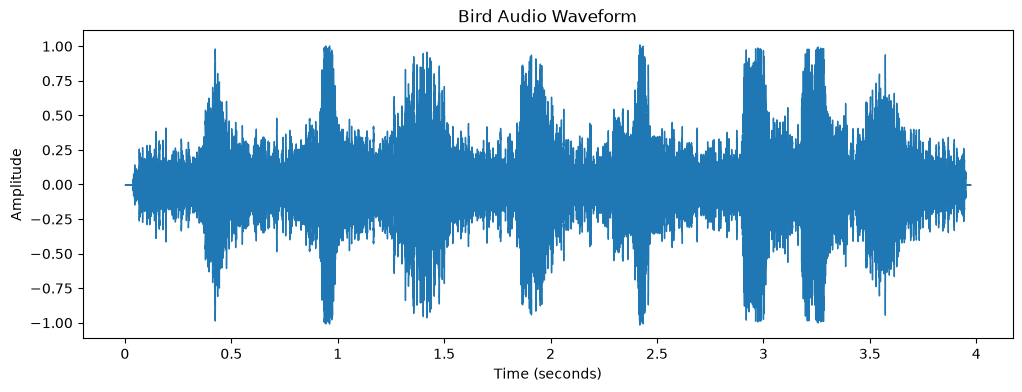

In [6]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(audio, sr=sr)

plt.title("Bird Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

In [7]:
from IPython.display import Audio

Audio(audio, rate=sr)

In [8]:
spectrogram = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

spectrogram_db = librosa.power_to_db(
    spectrogram,
    ref=np.max
)

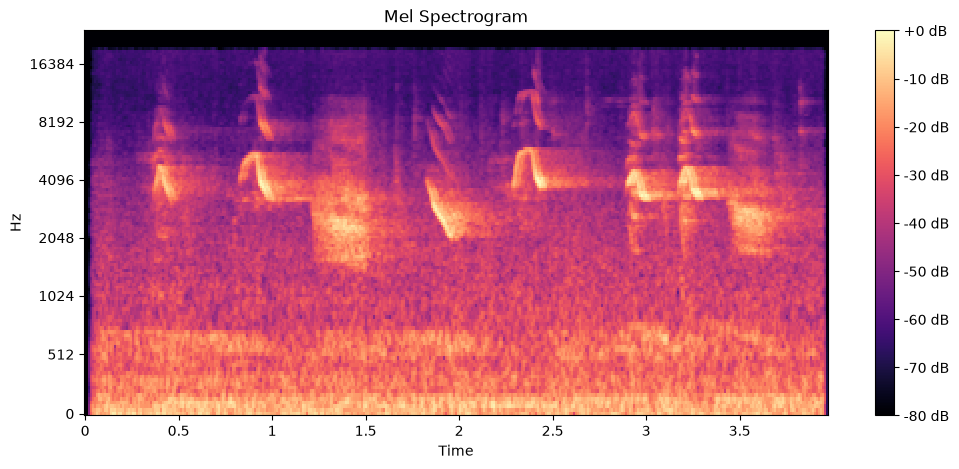

In [9]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    spectrogram_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")

plt.show()

In [10]:
print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")
print("Minimum amplitude:", audio.min())
print("Maximum amplitude:", audio.max())
print("Number of samples:", len(audio))

Sample rate: 48000
Duration: 3.9729791666666667 seconds
Minimum amplitude: -1.0015364
Maximum amplitude: 1.0124956
Number of samples: 190703


In [11]:
def preprocess_audio(path):
    audio, sr = librosa.load(
        path,
        sr=22050,
        mono=True
    )

    audio, _ = librosa.effects.trim(audio)

    return audio, sr

In [12]:
audio, sr = preprocess_audio(audio_path)

print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")

Sample rate: 22050
Duration: 3.973015873015873 seconds


In [13]:
segment_duration = 4

segment_samples = segment_duration * sr

segment = audio[:segment_samples]

print("Segment duration:", len(segment) / sr)

Segment duration: 3.973015873015873


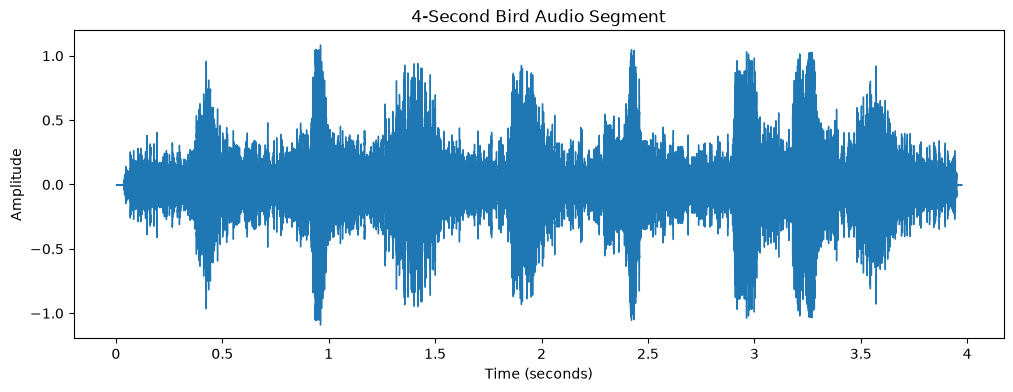

In [14]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(segment, sr=sr)

plt.title("4-Second Bird Audio Segment")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

In [15]:
mel = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

mel_db = librosa.power_to_db(
    mel,
    ref=np.max
)

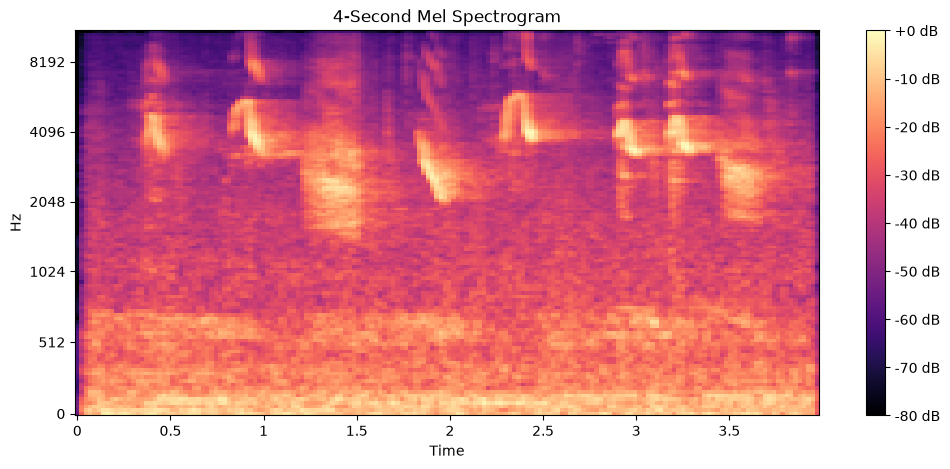

In [16]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("4-Second Mel Spectrogram")

plt.show()

In [17]:

print(mel_db.shape)

(128, 172)


In [18]:
mel_normalized = cv2.normalize(
    mel_db,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

mel_normalized = mel_normalized.astype(np.uint8)

In [19]:
print(mel_normalized.min())
print(mel_normalized.max())
print(mel_normalized.dtype)

0
255
uint8


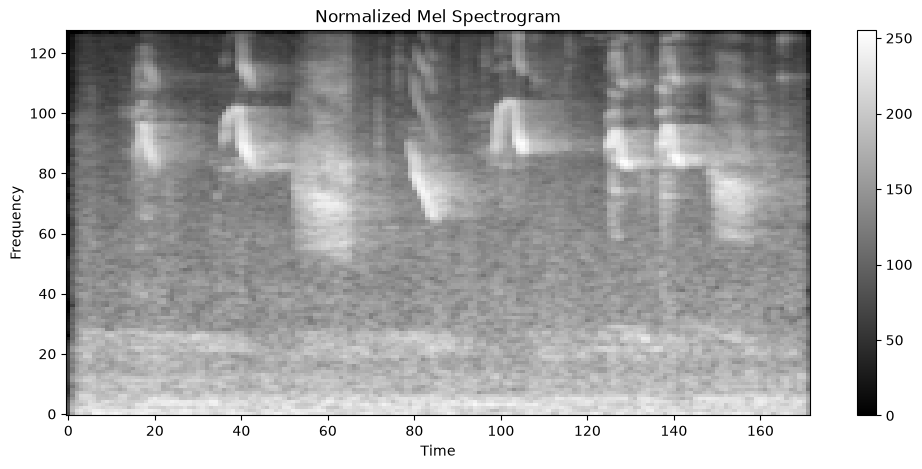

In [20]:
plt.figure(figsize=(12, 5))

plt.imshow(
    mel_normalized,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.title("Normalized Mel Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.colorbar()

plt.show()

In [21]:
gaussian = cv2.GaussianBlur(
    mel_normalized,
    (5, 5),
    0
)

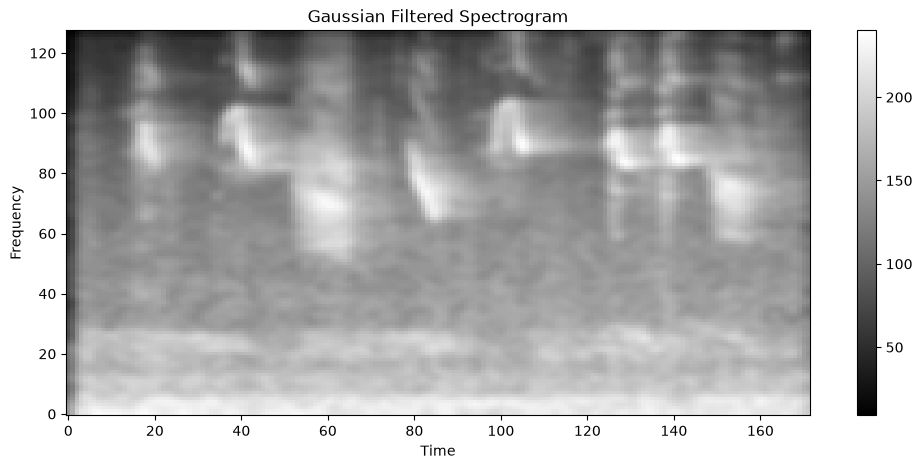

In [22]:
plt.figure(figsize=(12, 5))

plt.imshow(
    gaussian,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.title("Gaussian Filtered Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.colorbar()

plt.show()

In [23]:
median = cv2.medianBlur(
    mel_normalized,
    5
)

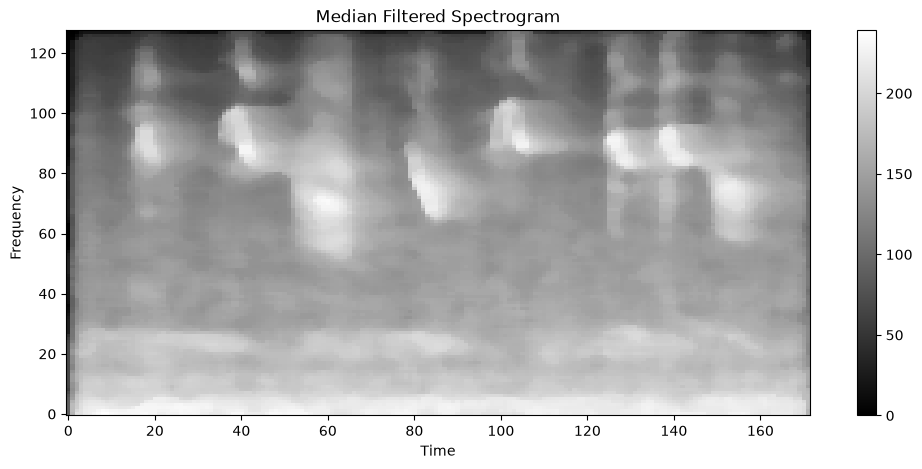

In [24]:
plt.figure(figsize=(12, 5))

plt.imshow(
    median,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.title("Median Filtered Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.colorbar()

plt.show()

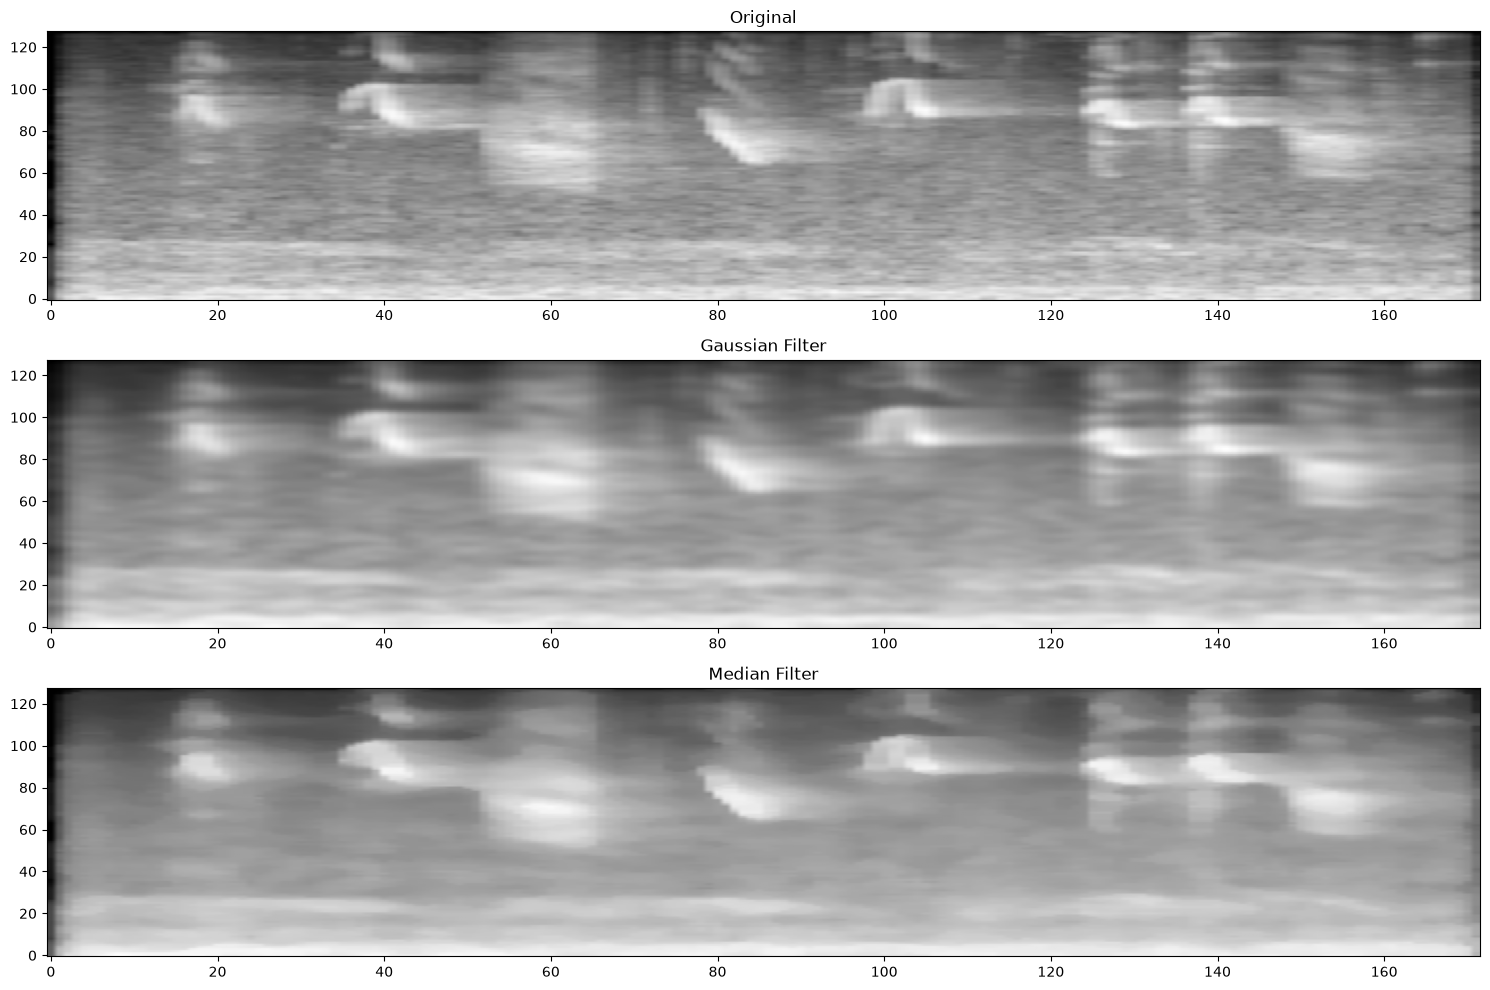

In [25]:
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.imshow(
    mel_normalized,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Original")

plt.subplot(3, 1, 2)
plt.imshow(
    gaussian,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Gaussian Filter")

plt.subplot(3, 1, 3)
plt.imshow(
    median,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Median Filter")

plt.tight_layout()
plt.show()

In [26]:
equalized = cv2.equalizeHist(
    mel_normalized
)

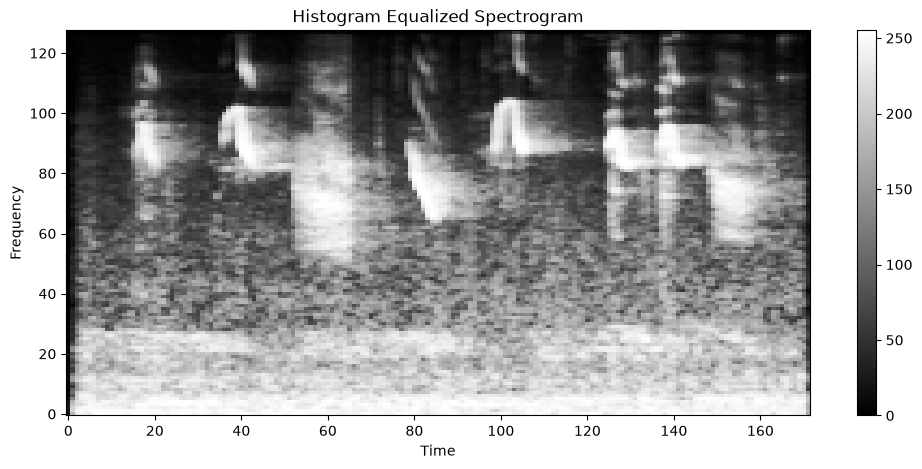

In [27]:
plt.figure(figsize=(12, 5))

plt.imshow(
    equalized,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.title("Histogram Equalized Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.colorbar()

plt.show()

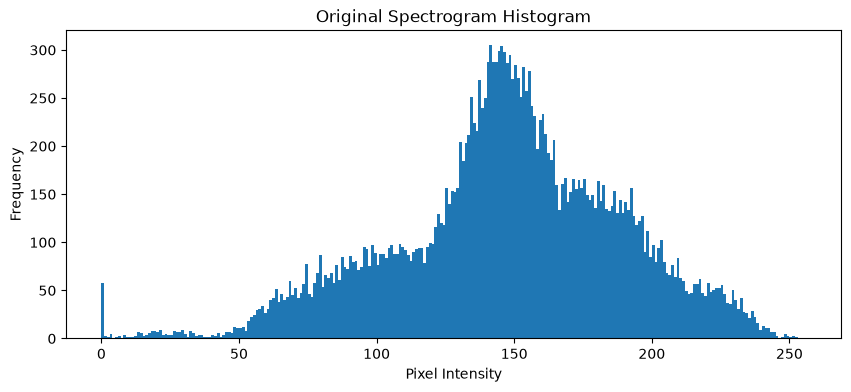

In [28]:
plt.figure(figsize=(10, 4))

plt.hist(
    mel_normalized.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title("Original Spectrogram Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

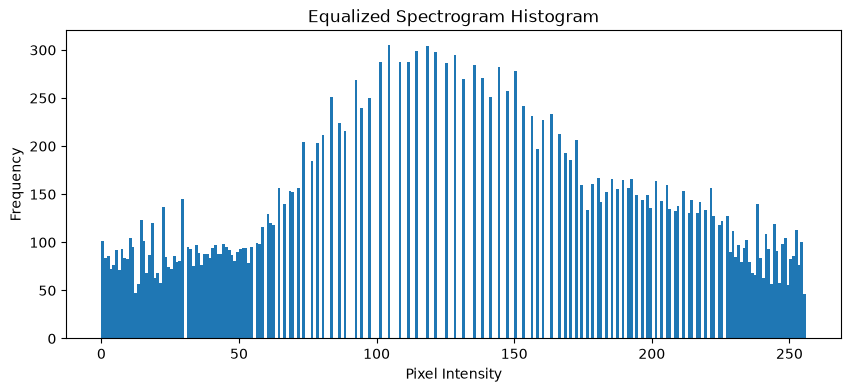

In [29]:
plt.figure(figsize=(10, 4))

plt.hist(
    equalized.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title("Equalized Spectrogram Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

In [30]:
enhanced = cv2.normalize(
    equalized,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

enhanced = enhanced.astype(np.uint8)

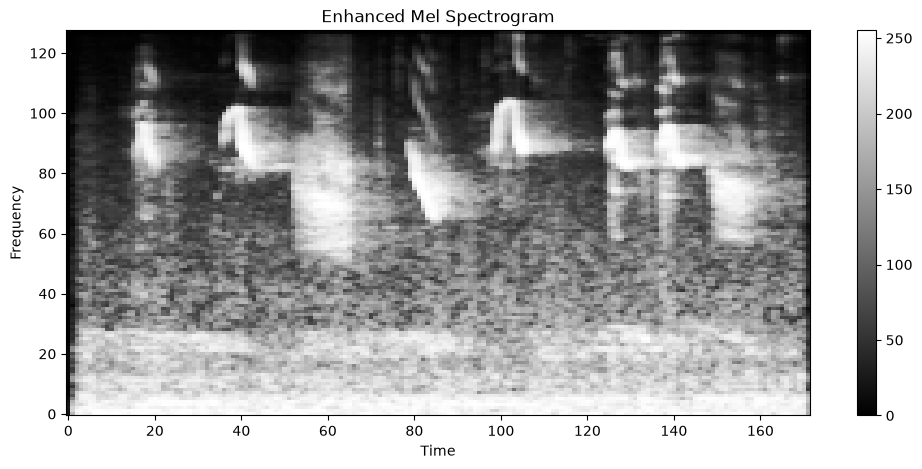

In [31]:
plt.figure(figsize=(12, 5))

plt.imshow(
    enhanced,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.title("Enhanced Mel Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.colorbar()

plt.show()

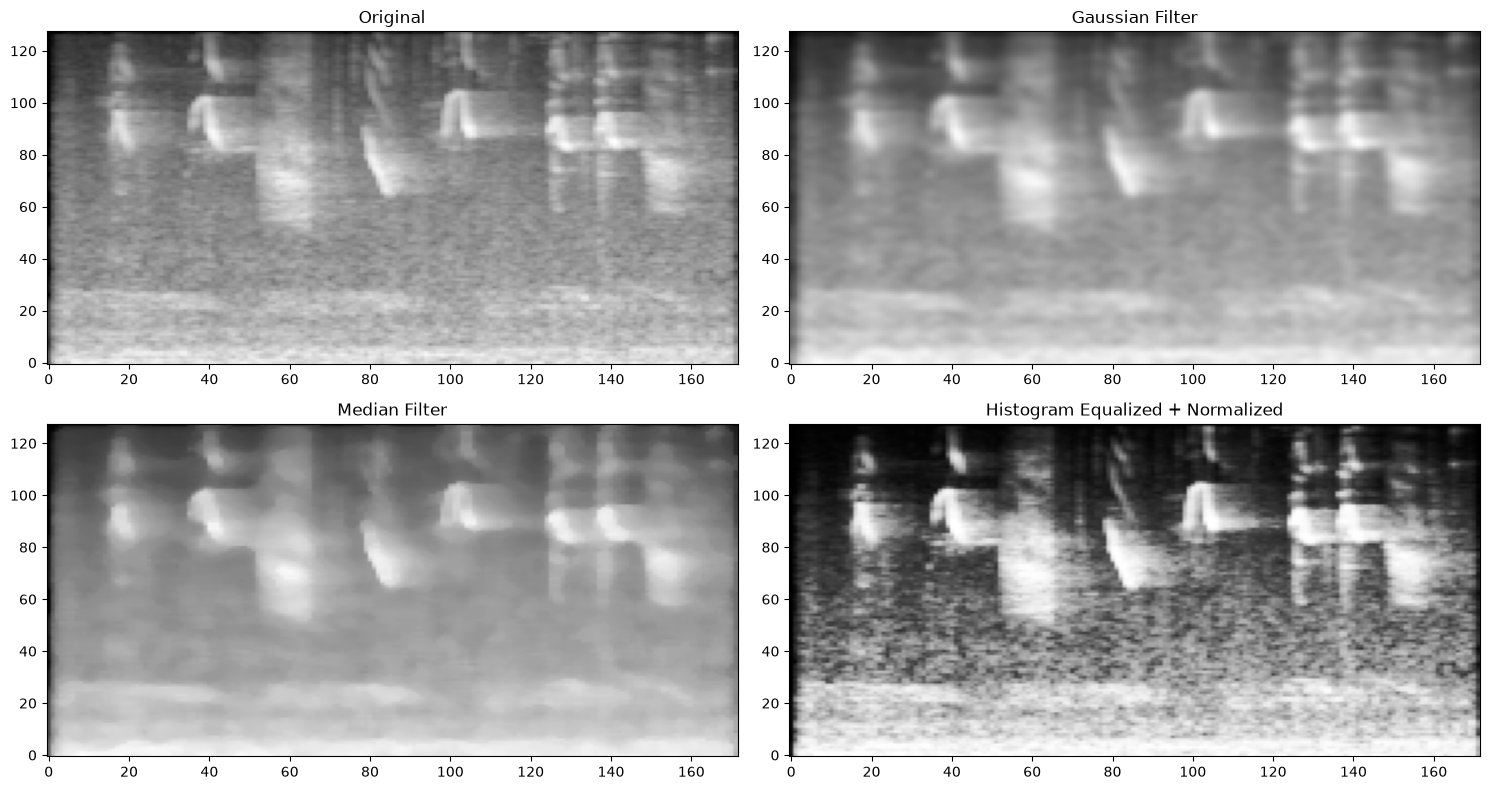

In [32]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(
    mel_normalized,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Original")

plt.subplot(2, 2, 2)
plt.imshow(
    gaussian,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Gaussian Filter")

plt.subplot(2, 2, 3)
plt.imshow(
    median,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Median Filter")

plt.subplot(2, 2, 4)
plt.imshow(
    enhanced,
    aspect="auto",
    origin="lower",
    cmap="gray"
)
plt.title("Histogram Equalized + Normalized")

plt.tight_layout()
plt.show()

In [33]:
def create_mel_spectrogram(audio):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=22050,
        n_mels=128,
        n_fft=2048,
        hop_length=512
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db

In [ ]:
def enhance_spectrogram(mel_db):

    normalized = cv2.normalize(
        mel_db,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    normalized = normalized.astype(np.uint8)

    gaussian = cv2.GaussianBlur(
        normalized,
        (5, 5),
        0
    )

    median = cv2.medianBlur(
        normalized,
        5
    )

    equalized = cv2.equalizeHist(
        normalized
    )

    enhanced = cv2.normalize(
        equalized,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    enhanced = enhanced.astype(np.uint8)

    return normalized, gaussian, median, enhanced

In [35]:
mel_db = create_mel_spectrogram(segment)

original, gaussian, median, enhanced = enhance_spectrogram(mel_db)

In [36]:
print("Original:", original.shape)
print("Gaussian:", gaussian.shape)
print("Median:", median.shape)
print("Enhanced:", enhanced.shape)

Original: (128, 172)
Gaussian: (128, 172)
Median: (128, 172)
Enhanced: (128, 172)


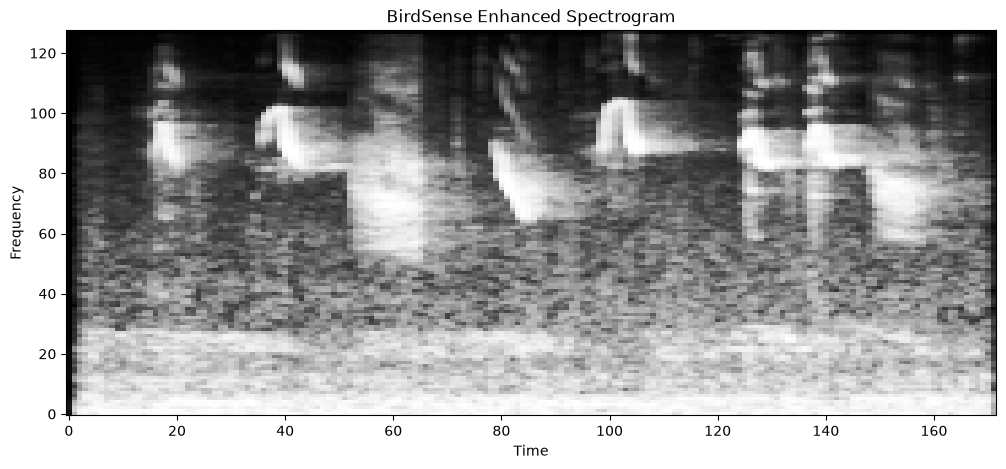

In [37]:
plt.figure(figsize=(12, 5))

plt.imshow(
    enhanced,
    aspect="auto",
    origin="lower",
    cmap="gray"
)

plt.title("BirdSense Enhanced Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.show()

In [38]:
def preprocess_audio(path):

    audio, sr = librosa.load(
        path,
        sr=22050,
        mono=True
    )

    audio, _ = librosa.effects.trim(audio)

    return audio, sr

In [39]:
audio, sr = preprocess_audio(audio_path)

segment = audio[:4 * sr]

mel_db = create_mel_spectrogram(segment)

original, gaussian, median, enhanced = enhance_spectrogram(mel_db)

In [40]:
from pathlib import Path
from collections import Counter

data_path = Path("../data/raw")

audio_files = list(data_path.rglob("*.mp3")) + list(data_path.rglob("*.wav"))

print("Total audio files:", len(audio_files))

species_count = Counter(file.parent.name for file in audio_files)

for species, count in sorted(species_count.items()):
    print(f"{species}: {count}")

Total audio files: 40
common_koel: 5
common_myna: 5
common_tailorbird: 5
greater_coucal: 5
house_sparrow: 5
indian_robin: 5
red_vented_bulbul: 5
rose_ringed_parakeet: 5


In [41]:
records = []

for file in audio_files:
    records.append({
        "recording_id": file.stem,
        "species": file.parent.name,
        "filename": file.name,
        "path": str(file)
    })

metadata = pd.DataFrame(records)

metadata.head()

,recording_id,species,filename,path
0,XC1089796 - Asian Koel - Eudynamys scolopaceus,common_koel,XC1089796 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1089796 - Asian Koel...
1,XC1096404 - Asian Koel - Eudynamys scolopaceus,common_koel,XC1096404 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1096404 - Asian Koel...
2,XC1163241 - Asian Koel - Eudynamys scolopaceus...,common_koel,XC1163241 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1163241 - Asian Koel...
3,XC1163242 - Asian Koel - Eudynamys scolopaceus...,common_koel,XC1163242 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1163242 - Asian Koel...
4,XC1175438 - Common Myna - Acridotheres tristis,common_myna,XC1175438 - Common Myna - Acridotheres tristis...,..\data\raw\common_myna\XC1175438 - Common Myn...


In [42]:
from pathlib import Path

metadata_dir = Path("../data/metadata").resolve()

print("Metadata folder:")
print(metadata_dir)

print("Exists:", metadata_dir.exists())

Metadata folder:
C:\Users\gavis\Desktop\BirdSense\data\metadata
Exists: True


In [43]:
metadata_dir.mkdir(parents=True, exist_ok=True)

print("Metadata folder ready.")

Metadata folder ready.


In [44]:
metadata.to_csv(
    metadata_dir / "recordings_new.csv",
    index=False
)

print("Saved:", len(metadata), "rows")

Saved: 40 rows


In [45]:
print(metadata.shape)
print(metadata.columns)

(40, 4)
Index(['recording_id', 'species', 'filename', 'path'], dtype='str')


In [46]:
print(metadata["species"].value_counts())

species
common_koel             5
common_myna             5
common_tailorbird       5
greater_coucal          5
house_sparrow           5
indian_robin            5
red_vented_bulbul       5
rose_ringed_parakeet    5
Name: count, dtype: int64


In [47]:
print(metadata["filename"].head(10))

0    XC1089796 - Asian Koel - Eudynamys scolopaceus...
1    XC1096404 - Asian Koel - Eudynamys scolopaceus...
2    XC1163241 - Asian Koel - Eudynamys scolopaceus...
3    XC1163242 - Asian Koel - Eudynamys scolopaceus...
4    XC1175438 - Common Myna - Acridotheres tristis...
5    XC864598 - Common Tailorbird - Orthotomus suto...
6    XC914180 - Common Tailorbird - Orthotomus suto...
7    XC1026108 - Greater Coucal - Centropus sinensi...
8    XC1027879 - Greater Coucal - Centropus sinensi...
9    XC1156447 - House Sparrow - Passer domesticus.mp3
Name: filename, dtype: str


In [48]:
from pathlib import Path

data_path = Path("../data/raw")

extensions = ["*.mp3", "*.wav", "*.flac", "*.ogg", "*.m4a"]

audio_files = []

for extension in extensions:
    audio_files.extend(data_path.rglob(extension))

print("Total audio files:", len(audio_files))

Total audio files: 40


In [49]:
species_count = Counter(file.parent.name for file in audio_files)

for species, count in sorted(species_count.items()):
    print(f"{species}: {count}")

common_koel: 5
common_myna: 5
common_tailorbird: 5
greater_coucal: 5
house_sparrow: 5
indian_robin: 5
red_vented_bulbul: 5
rose_ringed_parakeet: 5


In [50]:
records = []

for file in audio_files:
    records.append({
        "recording_id": file.stem,
        "species": file.parent.name,
        "filename": file.name,
        "path": str(file)
    })

metadata = pd.DataFrame(records)

print(metadata.shape)

(40, 4)


In [51]:
print(metadata["species"].value_counts())


species
common_koel             5
common_myna             5
common_tailorbird       5
greater_coucal          5
house_sparrow           5
indian_robin            5
red_vented_bulbul       5
rose_ringed_parakeet    5
Name: count, dtype: int64


In [52]:
from pathlib import Path

data_path = Path("../data/raw")

for folder in sorted(data_path.iterdir()):
    if folder.is_dir():
        files = list(folder.iterdir())
        print(folder.name, "→", len(files), "files")

common_koel → 5 files
common_myna → 5 files
common_tailorbird → 5 files
greater_coucal → 5 files
house_sparrow → 5 files
indian_robin → 5 files
red_vented_bulbul → 5 files
rose_ringed_parakeet → 5 files


In [53]:
metadata.shape

(40, 4)

In [54]:
def inspect_audio(path):

    audio, sr = librosa.load(
        path,
        sr=None,
        mono=False
    )

    if audio.ndim == 1:
        channels = 1
        duration = len(audio) / sr
    else:
        channels = audio.shape[0]
        duration = audio.shape[1] / sr

    return duration, sr, channels

In [55]:
durations = []
sample_rates = []
channels = []

for path in audio_files:

    duration, sr, ch = inspect_audio(path)

    durations.append(duration)
    sample_rates.append(sr)
    channels.append(ch)

metadata["duration"] = durations
metadata["sample_rate"] = sample_rates
metadata["channels"] = channels

print(metadata.shape)

(40, 7)


In [56]:
metadata.head()

,recording_id,species,filename,path,duration,sample_rate,channels
0,XC1089796 - Asian Koel - Eudynamys scolopaceus,common_koel,XC1089796 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1089796 - Asian Koel...,19.008000,48000,1
1,XC1096404 - Asian Koel - Eudynamys scolopaceus,common_koel,XC1096404 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1096404 - Asian Koel...,20.799208,48000,1
2,XC1163241 - Asian Koel - Eudynamys scolopaceus...,common_koel,XC1163241 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1163241 - Asian Koel...,30.603515,44100,2
3,XC1163242 - Asian Koel - Eudynamys scolopaceus...,common_koel,XC1163242 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1163242 - Asian Koel...,32.118617,44100,2
4,XC1175438 - Common Myna - Acridotheres tristis,common_myna,XC1175438 - Common Myna - Acridotheres tristis...,..\data\raw\common_myna\XC1175438 - Common Myn...,3.972979,48000,2


In [57]:
print("Shortest:", metadata["duration"].min())
print("Longest:", metadata["duration"].max())
print("Average:", metadata["duration"].mean())

Shortest: 3.9729791666666667
Longest: 128.19445833333333
Average: 38.94586746917517


In [58]:
print(metadata["sample_rate"].value_counts())

sample_rate
48000    25
44100    13
32000     2
Name: count, dtype: int64


In [59]:
metadata.to_csv(
    "../data/metadata/recordings.csv",
    index=False
)

print("Metadata saved successfully!")
print("Rows:", len(metadata))

Metadata saved successfully!
Rows: 40


In [60]:
metadata["duration"].describe()

count     40.000000
mean      38.945867
std       26.008089
min        3.972979
25%       23.350865
50%       29.619000
75%       43.381304
max      128.194458
Name: duration, dtype: float64

In [61]:
print(metadata["sample_rate"].value_counts())

sample_rate
48000    25
44100    13
32000     2
Name: count, dtype: int64


In [62]:
print(metadata["channels"].value_counts())

channels
2    27
1    13
Name: count, dtype: int64


In [63]:
class_counts = metadata["species"].value_counts()

print(class_counts)

species
common_koel             5
common_myna             5
common_tailorbird       5
greater_coucal          5
house_sparrow           5
indian_robin            5
red_vented_bulbul       5
rose_ringed_parakeet    5
Name: count, dtype: int64


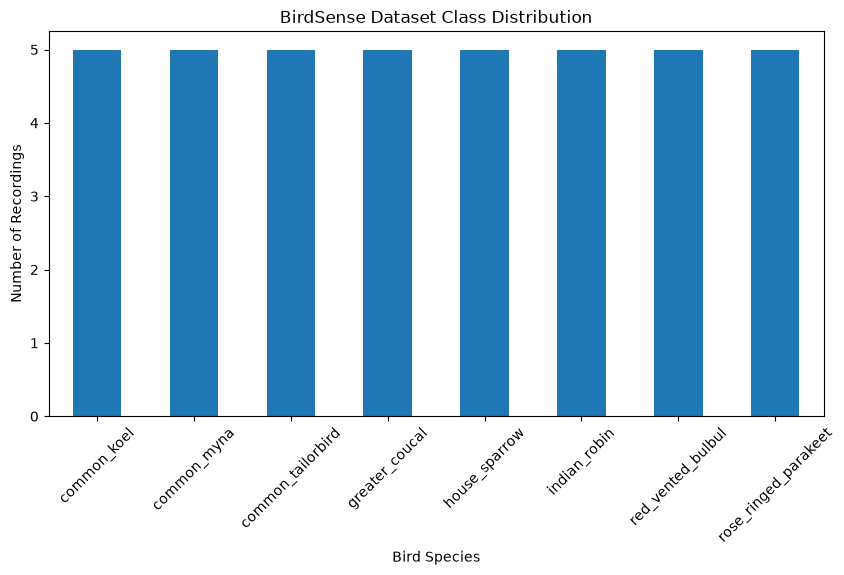

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

class_counts.plot(kind="bar")

plt.title("BirdSense Dataset Class Distribution")
plt.xlabel("Bird Species")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=45)

plt.show()

In [65]:
metadata.to_csv(
    "../data/metadata/recordings.csv",
    index=False
) 

print("Updated metadata saved.")

Updated metadata saved.


In [66]:
print(metadata.shape)

(40, 7)


In [67]:
metadata.head()

,recording_id,species,filename,path,duration,sample_rate,channels
0,XC1089796 - Asian Koel - Eudynamys scolopaceus,common_koel,XC1089796 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1089796 - Asian Koel...,19.008000,48000,1
1,XC1096404 - Asian Koel - Eudynamys scolopaceus,common_koel,XC1096404 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1096404 - Asian Koel...,20.799208,48000,1
2,XC1163241 - Asian Koel - Eudynamys scolopaceus...,common_koel,XC1163241 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1163241 - Asian Koel...,30.603515,44100,2
3,XC1163242 - Asian Koel - Eudynamys scolopaceus...,common_koel,XC1163242 - Asian Koel - Eudynamys scolopaceus...,..\data\raw\common_koel\XC1163242 - Asian Koel...,32.118617,44100,2
4,XC1175438 - Common Myna - Acridotheres tristis,common_myna,XC1175438 - Common Myna - Acridotheres tristis...,..\data\raw\common_myna\XC1175438 - Common Myn...,3.972979,48000,2


In [68]:
print(metadata["species"].value_counts())

species
common_koel             5
common_myna             5
common_tailorbird       5
greater_coucal          5
house_sparrow           5
indian_robin            5
red_vented_bulbul       5
rose_ringed_parakeet    5
Name: count, dtype: int64


In [69]:
print("Shortest recording:",
      metadata["duration"].min(),
      "seconds")

print("Longest recording:",
      metadata["duration"].max(),
      "seconds")

print("Average recording:",
      metadata["duration"].mean(),
      "seconds")

Shortest recording: 3.9729791666666667 seconds
Longest recording: 128.19445833333333 seconds
Average recording: 38.94586746917517 seconds


In [70]:
metadata["duration"].describe()

count     40.000000
mean      38.945867
std       26.008089
min        3.972979
25%       23.350865
50%       29.619000
75%       43.381304
max      128.194458
Name: duration, dtype: float64

In [71]:
print(metadata["sample_rate"].value_counts())

sample_rate
48000    25
44100    13
32000     2
Name: count, dtype: int64


In [72]:
print(metadata["channels"].value_counts())

channels
2    27
1    13
Name: count, dtype: int64


In [73]:
from sklearn.model_selection import train_test_split

In [74]:
train_val, test = train_test_split(
    metadata,
    test_size=0.20,
    stratify=metadata["species"],
    random_state=42
)

print("Train + Validation:", len(train_val))
print("Test:", len(test))

Train + Validation: 32
Test: 8


In [75]:
train, val = train_test_split(
    train_val,
    test_size=0.25,
    stratify=train_val["species"],
    random_state=42
)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Train: 24
Validation: 8
Test: 8


In [76]:
print("TRAIN")
print(train["species"].value_counts())

print("\nVALIDATION")
print(val["species"].value_counts())

print("\nTEST")
print(test["species"].value_counts())

TRAIN
species
indian_robin            3
rose_ringed_parakeet    3
common_myna             3
greater_coucal          3
common_tailorbird       3
house_sparrow           3
red_vented_bulbul       3
common_koel             3
Name: count, dtype: int64

VALIDATION
species
common_tailorbird       1
indian_robin            1
red_vented_bulbul       1
house_sparrow           1
common_myna             1
rose_ringed_parakeet    1
common_koel             1
greater_coucal          1
Name: count, dtype: int64

TEST
species
indian_robin            1
rose_ringed_parakeet    1
common_koel             1
common_myna             1
common_tailorbird       1
house_sparrow           1
greater_coucal          1
red_vented_bulbul       1
Name: count, dtype: int64


In [77]:
metadata["split"] = ""

metadata.loc[train.index, "split"] = "train"
metadata.loc[val.index, "split"] = "validation"
metadata.loc[test.index, "split"] = "test"

In [78]:
metadata["split"].value_counts()

split
train         24
test           8
validation     8
Name: count, dtype: int64

In [79]:
metadata.to_csv(
    "../data/metadata/recordings.csv",
    index=False
)

print("Updated metadata saved.")

Updated metadata saved.


In [80]:
def segment_audio(audio, sr, segment_duration=4):

    segment_length = int(segment_duration * sr)

    segments = []

    for start in range(0, len(audio), segment_length):

        end = start + segment_length

        segment = audio[start:end]

        if len(segment) == segment_length:
            segments.append(segment)

    return segments

In [81]:
test_path = audio_files[0]

audio, sr = preprocess_audio(test_path)

segments = segment_audio(
    audio,
    sr,
    segment_duration=4
)

print("Recording:", test_path.name)
print("Duration:", len(audio) / sr, "seconds")
print("Segments:", len(segments))
print("Segment shape:", segments[0].shape)

Recording: XC1089796 - Asian Koel - Eudynamys scolopaceus.mp3
Duration: 18.9615873015873 seconds
Segments: 4
Segment shape: (88200,)


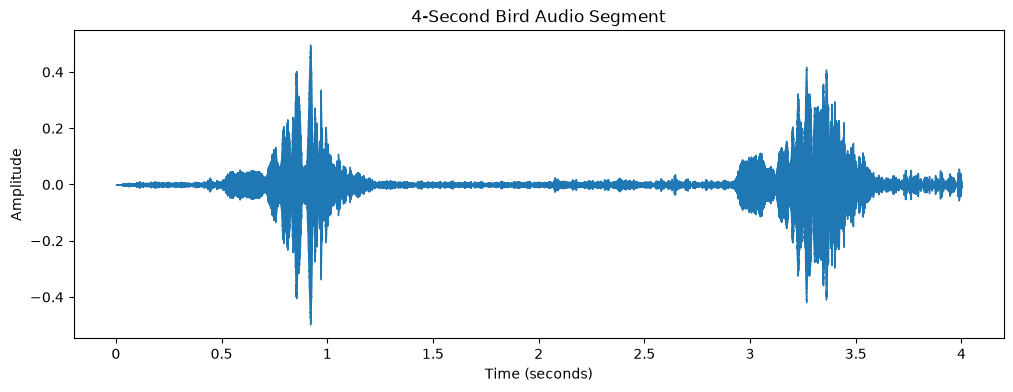

In [82]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(
    segments[0],
    sr=sr
)

plt.title("4-Second Bird Audio Segment")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

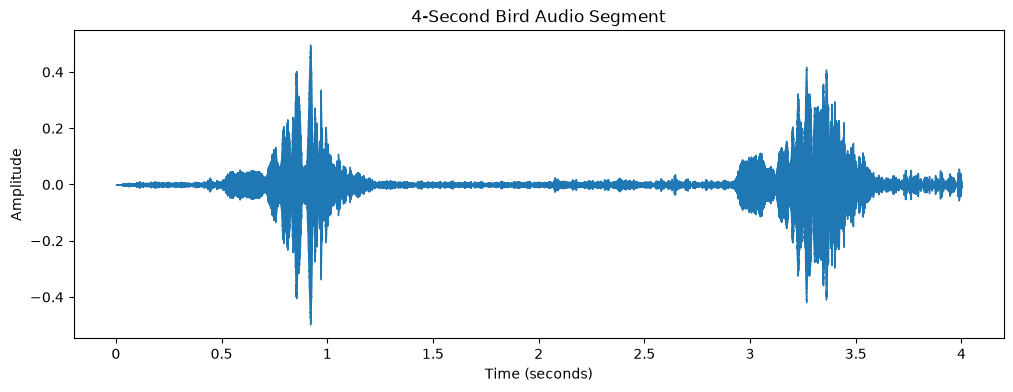

In [83]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(
    segments[0],
    sr=sr
)

plt.title("4-Second Bird Audio Segment")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

In [84]:
def process_recording(row):

    audio, sr = preprocess_audio(row["path"])

    segments = segment_audio(
        audio,
        sr,
        segment_duration=4
    )

    output_dir = (
        processed_dir
        / row["split"]
        / row["species"]
    )

    saved_files = []

    for i, segment in enumerate(segments):

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_mels=128,
            n_fft=2048,
            hop_length=512
        )

        mel_db = librosa.power_to_db(
            mel,
            ref=np.max
        )

        normalized, gaussian, median, enhanced = enhance_spectrogram(
            mel_db
        )

        output_path = (
            output_dir
            / f"{row['recording_id']}_segment_{i+1}.png"
        )

        plt.imsave(
            output_path,
            enhanced,
            cmap="gray"
        )

        saved_files.append(str(output_path))

    return saved_files

In [85]:
from pathlib import Path

processed_dir = Path("../data/processed")

splits = ["train", "validation", "test"]

species_list = sorted(metadata["species"].unique())

for split in splits:
    for species in species_list:
        folder = processed_dir / split / species
        folder.mkdir(parents=True, exist_ok=True)

print("Processed dataset folders ready.")

Processed dataset folders ready.


In [86]:
test_row = metadata.iloc[0]

saved = process_recording(test_row)

print("Saved:", len(saved), "images")
print(saved)

Saved: 4 images
['..\\data\\processed\\train\\common_koel\\XC1089796 - Asian Koel - Eudynamys scolopaceus_segment_1.png', '..\\data\\processed\\train\\common_koel\\XC1089796 - Asian Koel - Eudynamys scolopaceus_segment_2.png', '..\\data\\processed\\train\\common_koel\\XC1089796 - Asian Koel - Eudynamys scolopaceus_segment_3.png', '..\\data\\processed\\train\\common_koel\\XC1089796 - Asian Koel - Eudynamys scolopaceus_segment_4.png']


In [87]:
all_saved_files = []

for _, row in metadata.iterrows():

    saved_files = process_recording(row)

    all_saved_files.extend(saved_files)

print("Total images generated:", len(all_saved_files))

Total images generated: 367


In [88]:
from collections import Counter

print(Counter(
    Path(path).parts[-2]
    for path in all_saved_files
))

Counter({'greater_coucal': 68, 'house_sparrow': 67, 'common_tailorbird': 61, 'common_koel': 55, 'common_myna': 33, 'red_vented_bulbul': 30, 'rose_ringed_parakeet': 28, 'indian_robin': 25})


In [89]:
print("Total images:", len(all_saved_files))

Total images: 367


In [90]:
from collections import Counter
from pathlib import Path

split_counts = Counter()
species_counts = Counter()

for path in all_saved_files:

    p = Path(path)

    split = p.parts[-3]
    species = p.parts[-2]

    split_counts[split] += 1
    species_counts[species] += 1

print("Images by split:")
print(split_counts)

print("\nImages by species:")
print(species_counts)

print("\nTotal images:", len(all_saved_files))

Images by split:
Counter({'train': 221, 'validation': 81, 'test': 65})

Images by species:
Counter({'greater_coucal': 68, 'house_sparrow': 67, 'common_tailorbird': 61, 'common_koel': 55, 'common_myna': 33, 'red_vented_bulbul': 30, 'rose_ringed_parakeet': 28, 'indian_robin': 25})

Total images: 367


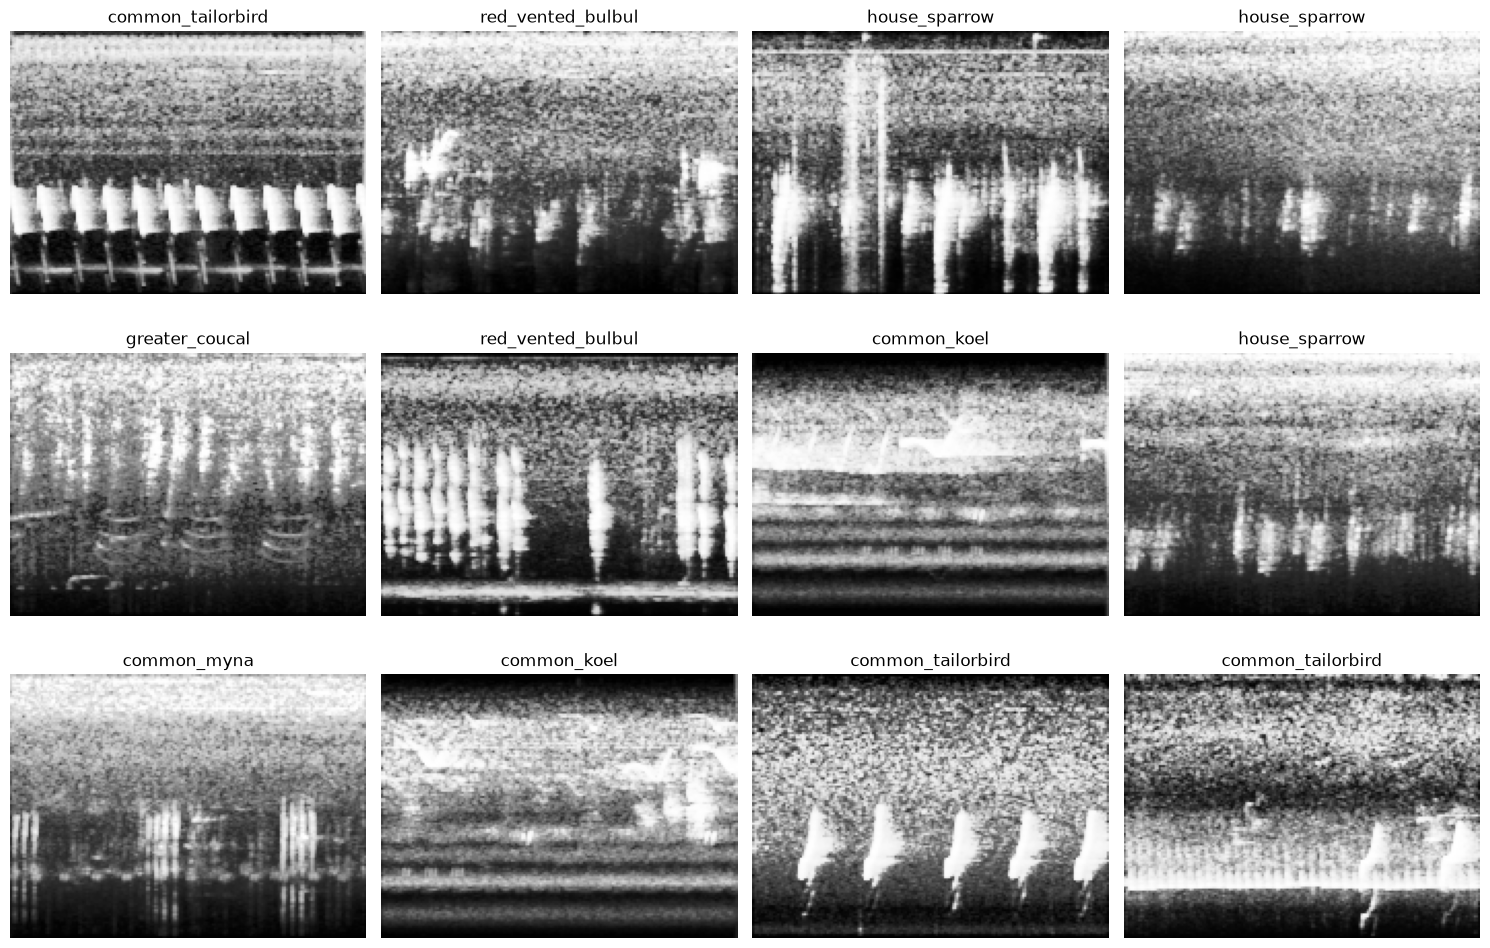

In [91]:
import random
from pathlib import Path
import matplotlib.pyplot as plt

sample_paths = random.sample(all_saved_files, 12)

plt.figure(figsize=(15, 10))

for i, path in enumerate(sample_paths):

    image = plt.imread(path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.axis("off")

    species = Path(path).parts[-2]
    plt.title(species)

plt.tight_layout()
plt.show()

In [92]:
from PIL import Image

image = Image.open(all_saved_files[0])

print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (173, 128)
Image mode: RGBA


In [93]:
import pandas as pd
from pathlib import Path

rows = []

for path in all_saved_files:

    p = Path(path)

    rows.append({
        "split": p.parts[-3],
        "species": p.parts[-2]
    })

image_metadata = pd.DataFrame(rows)

print(
    pd.crosstab(
        image_metadata["species"],
        image_metadata["split"]
    )
)

split                 test  train  validation
species                                      
common_koel              7     16          32
common_myna              8     15          10
common_tailorbird       15     33          13
greater_coucal          19     42           7
house_sparrow            4     56           7
indian_robin             2     20           3
red_vented_bulbul        6     18           6
rose_ringed_parakeet     4     21           3


In [94]:
species_names = sorted(metadata["species"].unique())

class_to_index = {
    species: i
    for i, species in enumerate(species_names)
}

index_to_class = {
    i: species
    for species, i in class_to_index.items()
}

print("Classes:")
print(class_to_index)

Classes:
{'common_koel': 0, 'common_myna': 1, 'common_tailorbird': 2, 'greater_coucal': 3, 'house_sparrow': 4, 'indian_robin': 5, 'red_vented_bulbul': 6, 'rose_ringed_parakeet': 7}


In [95]:
import cv2
import numpy as np

IMG_WIDTH = 172
IMG_HEIGHT = 128

def load_image(path):

    image = cv2.imread(
        str(path),
        cv2.IMREAD_GRAYSCALE
    )

    image = cv2.resize(
        image,
        (IMG_WIDTH, IMG_HEIGHT)
    )

    image = image.astype(np.float32) / 255.0

    image = np.expand_dims(
        image,
        axis=-1
    )

    return image

In [96]:
test_image = load_image(all_saved_files[0])

print("Shape:", test_image.shape)
print("Minimum:", test_image.min())
print("Maximum:", test_image.max())

Shape: (128, 172, 1)
Minimum: 0.0
Maximum: 1.0


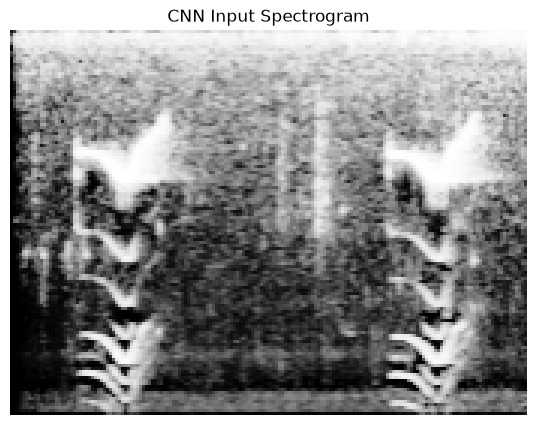

In [97]:
plt.figure(figsize=(10, 5))

plt.imshow(
    test_image.squeeze(),
    cmap="gray"
)

plt.title("CNN Input Spectrogram")
plt.axis("off")

plt.show()

In [98]:
import numpy as np
from pathlib import Path

X_train = []
y_train = []

X_validation = []
y_validation = []

X_test = []
y_test = []

for path in all_saved_files:

    path = Path(path)

    split = path.parts[-3]
    species = path.parts[-2]

    image = load_image(path)
    label = class_to_index[species]

    if split == "train":
        X_train.append(image)
        y_train.append(label)

    elif split == "validation":
        X_validation.append(image)
        y_validation.append(label)

    elif split == "test":
        X_test.append(image)
        y_test.append(label)

In [99]:
X_train = np.array(X_train)
y_train = np.array(y_train)

X_validation = np.array(X_validation)
y_validation = np.array(y_validation)

X_test = np.array(X_test)
y_test = np.array(y_test)

In [100]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (221, 128, 172, 1)
y_train: (221,)
X_validation: (81, 128, 172, 1)
y_validation: (81,)
X_test: (65, 128, 172, 1)
y_test: (65,)


In [101]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = len(class_to_index)

model = models.Sequential([

    layers.Input(shape=(128, 172, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 170, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 85, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 83, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 41, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 39, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 19, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 34048)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,358,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │           1,032 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,451,976 (16.98 MB)

 Trainable params: 4,451,976 (16.98 MB)

 Non-trainable params: 0 (0.00 B)

In [102]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [103]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:")

for class_index, weight in class_weights.items():
    print(
        index_to_class[class_index],
        ":", 
        round(weight, 3)
    )

Class weights:
common_koel : 1.727
common_myna : 1.842
common_tailorbird : 0.837
greater_coucal : 0.658
house_sparrow : 0.493
indian_robin : 1.381
red_vented_bulbul : 1.535
rose_ringed_parakeet : 1.315


In [104]:
history_data = {
    "accuracy": [],
    "loss": [],
    "val_accuracy": [],
    "val_loss": []
}

In [105]:
for epoch in range(15):

    print(f"\n========== Epoch {epoch + 1}/15 ==========")

    result = model.fit(
        X_train,
        y_train,
        validation_data=(X_validation, y_validation),
        epochs=1,
        batch_size=32,
        class_weight=class_weights,
        verbose=1
    )

    history_data["accuracy"].append(result.history["accuracy"][0])
    history_data["loss"].append(result.history["loss"][0])
    history_data["val_accuracy"].append(result.history["val_accuracy"][0])
    history_data["val_loss"].append(result.history["val_loss"][0])

    print("Epoch completed successfully.")


========== Epoch 1/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 927ms/step - accuracy: 0.1222 - loss: 2.2274 - val_accuracy: 0.0370 - val_loss: 2.1031
Epoch completed successfully.

========== Epoch 2/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 825ms/step - accuracy: 0.0995 - loss: 2.0716 - val_accuracy: 0.0123 - val_loss: 2.0830
Epoch completed successfully.

========== Epoch 3/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 854ms/step - accuracy: 0.2353 - loss: 2.0026 - val_accuracy: 0.3086 - val_loss: 1.9749
Epoch completed successfully.

========== Epoch 4/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 802ms/step - accuracy: 0.3394 - loss: 1.8222 - val_accuracy: 0.4321 - val_loss: 1.8422
Epoch completed successfully.

========== Epoch 5/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 865ms/step - accuracy: 0.3846 - loss: 1.5989 - val_accuracy: 0.1481 - val_loss: 2.0463
Epoch completed successfully.

========== Epoch 6/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 823ms/step - accuracy: 0.4977 - loss: 1.44

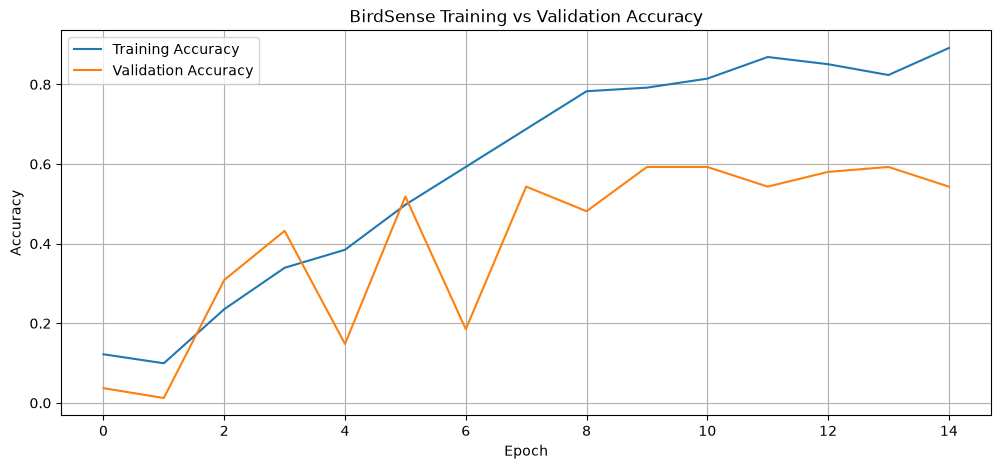

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(history_data["accuracy"], label="Training Accuracy")
plt.plot(history_data["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BirdSense Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

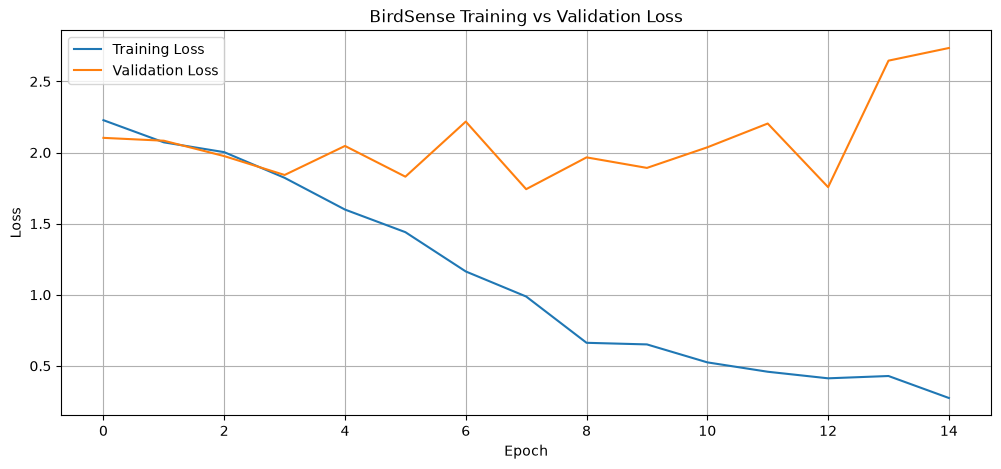

In [107]:
plt.figure(figsize=(12, 5))

plt.plot(history_data["loss"], label="Training Loss")
plt.plot(history_data["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BirdSense Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [108]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.2769 - loss: 2.5724
Test Loss: 2.5723800659179688
Test Accuracy: 0.2769230902194977


In [109]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions generated.")
print("Number of predictions:", len(y_pred))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
Predictions generated.
Number of predictions: 65


In [110]:
class_names = sorted(metadata["species"].unique())

print(class_names)

['common_koel', 'common_myna', 'common_tailorbird', 'greater_coucal', 'house_sparrow', 'indian_robin', 'red_vented_bulbul', 'rose_ringed_parakeet']


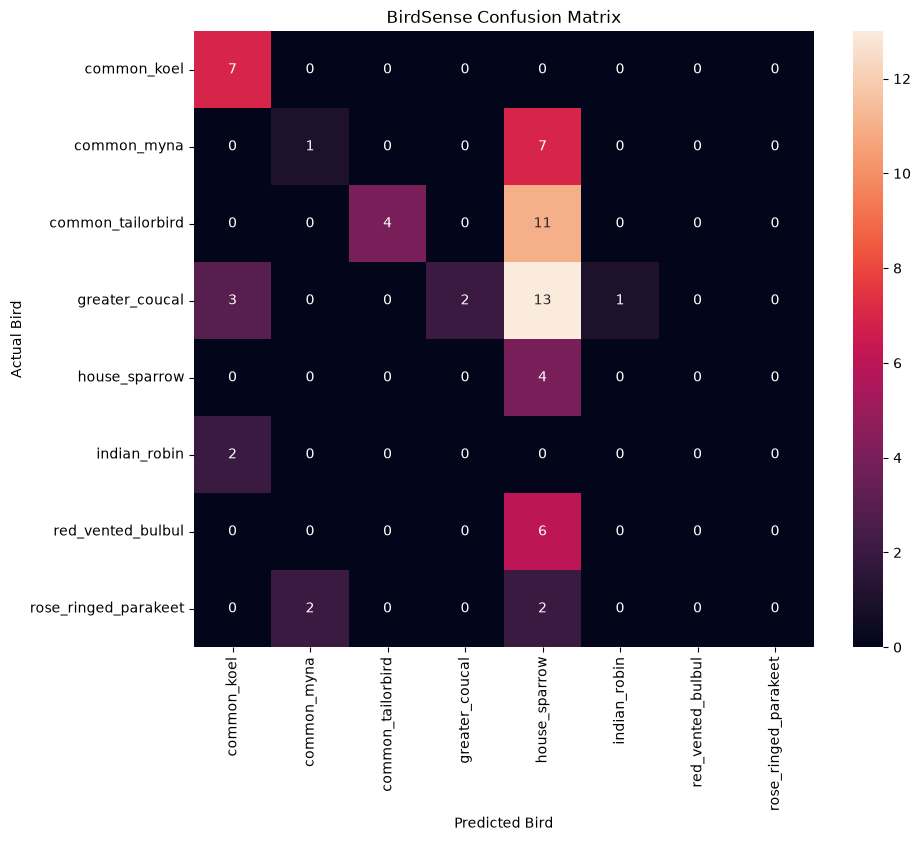

In [111]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Bird")
plt.ylabel("Actual Bird")
plt.title("BirdSense Confusion Matrix")

plt.show()

In [112]:
print("Test samples:", len(y_test))
print("Predictions:", len(y_pred))
print("Classes:", class_names)

Test samples: 65
Predictions: 65
Classes: ['common_koel', 'common_myna', 'common_tailorbird', 'greater_coucal', 'house_sparrow', 'indian_robin', 'red_vented_bulbul', 'rose_ringed_parakeet']


In [113]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

                      precision    recall  f1-score   support

         common_koel       0.58      1.00      0.74         7
         common_myna       0.33      0.12      0.18         8
   common_tailorbird       1.00      0.27      0.42        15
      greater_coucal       1.00      0.11      0.19        19
       house_sparrow       0.09      1.00      0.17         4
        indian_robin       0.00      0.00      0.00         2
   red_vented_bulbul       0.00      0.00      0.00         6
rose_ringed_parakeet       0.00      0.00      0.00         4

            accuracy                           0.28        65
           macro avg       0.38      0.31      0.21        65
        weighted avg       0.63      0.28      0.27        65



C:\Users\gavis\.conda\envs\birdsense\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gavis\.conda\envs\birdsense\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gavis\.conda\envs\birdsense\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

In [114]:
import tensorflow as tf
from tensorflow.keras import layers, models

model_v2 = models.Sequential([
    layers.Input(shape=(128, 172, 1)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    layers.Conv2D(32, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(256, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(8, activation="softmax")
])

model_v2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)             │ (None, 128, 172, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 128, 172, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 128, 172, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 128, 172, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 172, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 64, 86, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 64, 86, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 86, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 32, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 32, 43, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 43, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 16, 21, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 16, 21, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16, 21, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 8)                   │           1,032 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 423,688 (1.62 MB)

 Trainable params: 422,728 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [115]:
history_v2 = model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=1,
    batch_size=16,
    class_weight=class_weights,
    verbose=1
)

14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 982ms/step - accuracy: 0.3032 - loss: 1.8467 - val_accuracy: 0.1235 - val_loss: 2.1591


In [116]:
history_v2 = model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=1,
    batch_size=16,
    class_weight=class_weights,
    verbose=1
)

14/14 ━━━━━━━━━━━━━━━━━━━━ 13s 951ms/step - accuracy: 0.4253 - loss: 1.4790 - val_accuracy: 0.1235 - val_loss: 2.5591


In [117]:
history_v2 = model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=1,
    batch_size=16,
    class_weight=class_weights,
    verbose=1
)

14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 967ms/step - accuracy: 0.5204 - loss: 1.1901 - val_accuracy: 0.1235 - val_loss: 3.6992


In [118]:
history_data_v2 = {
    "accuracy": [],
    "loss": [],
    "val_accuracy": [],
    "val_loss": []
}

for epoch in range(15):

    print(f"\n========== Epoch {epoch + 1}/15 ==========")

    result = model_v2.fit(
        X_train,
        y_train,
        validation_data=(X_validation, y_validation),
        epochs=1,
        batch_size=32,
        class_weight=class_weights,
        verbose=1
    )

    history_data_v2["accuracy"].append(result.history["accuracy"][0])
    history_data_v2["loss"].append(result.history["loss"][0])
    history_data_v2["val_accuracy"].append(result.history["val_accuracy"][0])
    history_data_v2["val_loss"].append(result.history["val_loss"][0])

    model_v2.save("../models/birdsense_v2_latest.keras")

    print("Epoch completed successfully.")


========== Epoch 1/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5520 - loss: 1.1498 - val_accuracy: 0.1235 - val_loss: 3.9363
Epoch completed successfully.

========== Epoch 2/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.7149 - loss: 0.9426 - val_accuracy: 0.1235 - val_loss: 4.3248
Epoch completed successfully.

========== Epoch 3/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7376 - loss: 0.8047 - val_accuracy: 0.1235 - val_loss: 4.6805
Epoch completed successfully.

========== Epoch 4/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7692 - loss: 0.7680 - val_accuracy: 0.1235 - val_loss: 5.5997
Epoch completed successfully.

========== Epoch 5/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7466 - loss: 0.7084 - val_accuracy: 0.1235 - val_loss: 6.0924
Epoch completed successfully.

========== Epoch 6/15 ==========
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7873 - loss: 0.6742 - val_accu

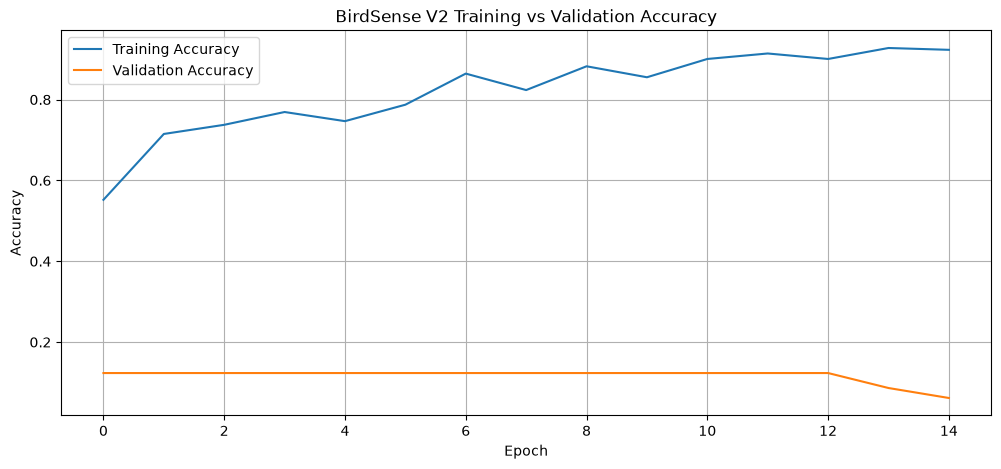

In [119]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(history_data_v2["accuracy"], label="Training Accuracy")
plt.plot(history_data_v2["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BirdSense V2 Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

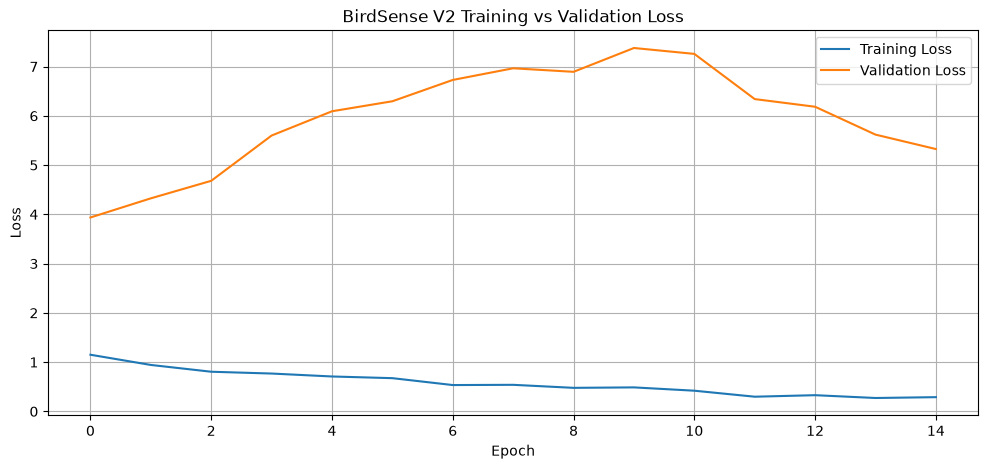

In [120]:
plt.figure(figsize=(12, 5))

plt.plot(history_data_v2["loss"], label="Training Loss")
plt.plot(history_data_v2["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BirdSense V2 Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [121]:
test_loss_v2, test_accuracy_v2 = model_v2.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("V2 Test Loss:", test_loss_v2)
print("V2 Test Accuracy:", test_accuracy_v2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step - accuracy: 0.0923 - loss: 6.1160
V2 Test Loss: 6.1159987449646
V2 Test Accuracy: 0.0923076942563057


In [122]:
y_pred_v2 = model_v2.predict(X_test)

y_pred_v2 = y_pred_v2.argmax(axis=1)

print("Predictions generated.")
print("Number of predictions:", len(y_pred_v2))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 347ms/step
Predictions generated.
Number of predictions: 65


In [123]:
from collections import Counter

print(Counter(y_pred_v2))

Counter({np.int64(1): 30, np.int64(4): 27, np.int64(7): 8})


In [124]:
print(class_names)
print("Class 1 =", class_names[1])

['common_koel', 'common_myna', 'common_tailorbird', 'greater_coucal', 'house_sparrow', 'indian_robin', 'red_vented_bulbul', 'rose_ringed_parakeet']
Class 1 = common_myna


In [125]:
print("Actual test classes:")
print(Counter(y_test))

Actual test classes:
Counter({np.int64(3): 19, np.int64(2): 15, np.int64(1): 8, np.int64(0): 7, np.int64(6): 6, np.int64(4): 4, np.int64(7): 4, np.int64(5): 2})


In [126]:
print("Training classes:")
print(Counter(y_train))

print("\nValidation classes:")
print(Counter(y_validation))

print("\nClass weights:")
print(class_weights)

Training classes:
Counter({np.int64(4): 56, np.int64(3): 42, np.int64(2): 33, np.int64(7): 21, np.int64(5): 20, np.int64(6): 18, np.int64(0): 16, np.int64(1): 15})

Validation classes:
Counter({np.int64(0): 32, np.int64(2): 13, np.int64(1): 10, np.int64(4): 7, np.int64(3): 7, np.int64(6): 6, np.int64(5): 3, np.int64(7): 3})

Class weights:
{np.int64(0): np.float64(1.7265625), np.int64(1): np.float64(1.8416666666666666), np.int64(2): np.float64(0.8371212121212122), np.int64(3): np.float64(0.6577380952380952), np.int64(4): np.float64(0.49330357142857145), np.int64(5): np.float64(1.38125), np.int64(6): np.float64(1.5347222222222223), np.int64(7): np.float64(1.3154761904761905)}


In [127]:
model.evaluate(
    X_test,
    y_test,
    verbose=1
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.2769 - loss: 2.5724


[2.5723800659179688, 0.2769230902194977]

In [128]:
y_pred = model.predict(X_test)

y_pred = y_pred.argmax(axis=1)

print("Predictions generated.")
print("Number of predictions:", len(y_pred))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 167ms/step
Predictions generated.
Number of predictions: 65


In [129]:
from collections import Counter

print("Predicted classes:")
print(Counter(y_pred))

Predicted classes:
Counter({np.int64(4): 43, np.int64(0): 12, np.int64(2): 4, np.int64(1): 3, np.int64(3): 2, np.int64(5): 1})


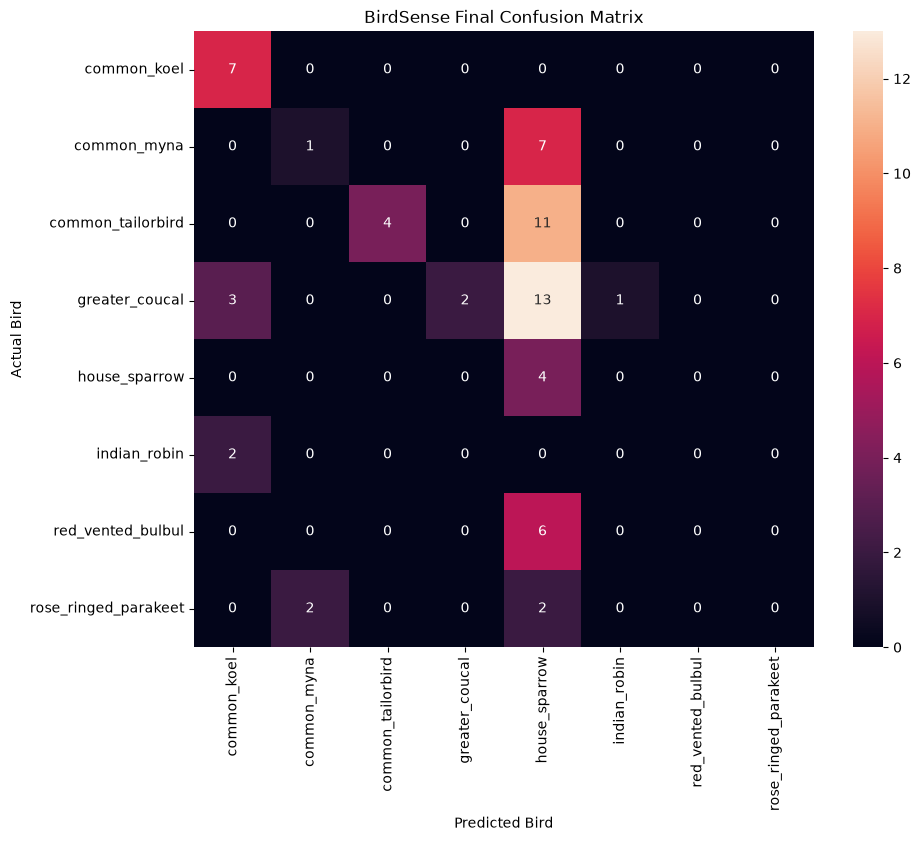

In [130]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Bird")
plt.ylabel("Actual Bird")
plt.title("BirdSense Final Confusion Matrix")

plt.show()

In [131]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))

                      precision    recall  f1-score   support

         common_koel       0.58      1.00      0.74         7
         common_myna       0.33      0.12      0.18         8
   common_tailorbird       1.00      0.27      0.42        15
      greater_coucal       1.00      0.11      0.19        19
       house_sparrow       0.09      1.00      0.17         4
        indian_robin       0.00      0.00      0.00         2
   red_vented_bulbul       0.00      0.00      0.00         6
rose_ringed_parakeet       0.00      0.00      0.00         4

            accuracy                           0.28        65
           macro avg       0.38      0.31      0.21        65
        weighted avg       0.63      0.28      0.27        65



In [132]:
model.save("../models/birdsense_final.keras")

print("Final BirdSense model saved successfully.")

Final BirdSense model saved successfully.


In [133]:
from tensorflow.keras.models import load_model

final_model = load_model("../models/birdsense_final.keras")

print("Final model loaded successfully.")

Final model loaded successfully.


In [134]:
sample = X_test[0]

prediction = final_model.predict(sample[np.newaxis, ...], verbose=0)

predicted_class = prediction.argmax(axis=1)[0]

print("Actual bird:", class_names[y_test[0]])
print("Predicted bird:", class_names[predicted_class])

Actual bird: common_koel
Predicted bird: common_koel


In [135]:
test_path = audio_files[0]

audio, sr = preprocess_audio(test_path)

segments = segment_audio(
    audio,
    sr,
    segment_duration=4
)

print("Recording:", test_path.name)
print("Segments:", len(segments))

Recording: XC1089796 - Asian Koel - Eudynamys scolopaceus.mp3
Segments: 4


In [136]:
import numpy as np
import librosa

def predict_bird(audio_path):

    audio, sr = preprocess_audio(audio_path)

    segments = segment_audio(
        audio,
        sr,
        segment_duration=4
    )

    predictions = []

    for segment in segments:

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_mels=128
        )

        mel_db = librosa.power_to_db(mel, ref=np.max)

        mel_db = librosa.util.fix_length(
            mel_db,
            size=172,
            axis=1
        )

        mel_db = (mel_db - mel_db.min()) / (
            mel_db.max() - mel_db.min() + 1e-8
        )

        image = mel_db[..., np.newaxis]

        image = image[np.newaxis, ...]

        prediction = final_model.predict(
            image,
            verbose=0
        )[0]

        predictions.append(prediction)

    predictions = np.array(predictions)

    final_prediction = predictions.mean(axis=0)

    predicted_class = np.argmax(final_prediction)

    confidence = final_prediction[predicted_class]

    return class_names[predicted_class], confidence

In [137]:
bird, confidence = predict_bird(test_path)

print("BirdSense Prediction:", bird)
print("Confidence:", round(confidence * 100, 2), "%")

BirdSense Prediction: common_koel
Confidence: 93.88 %


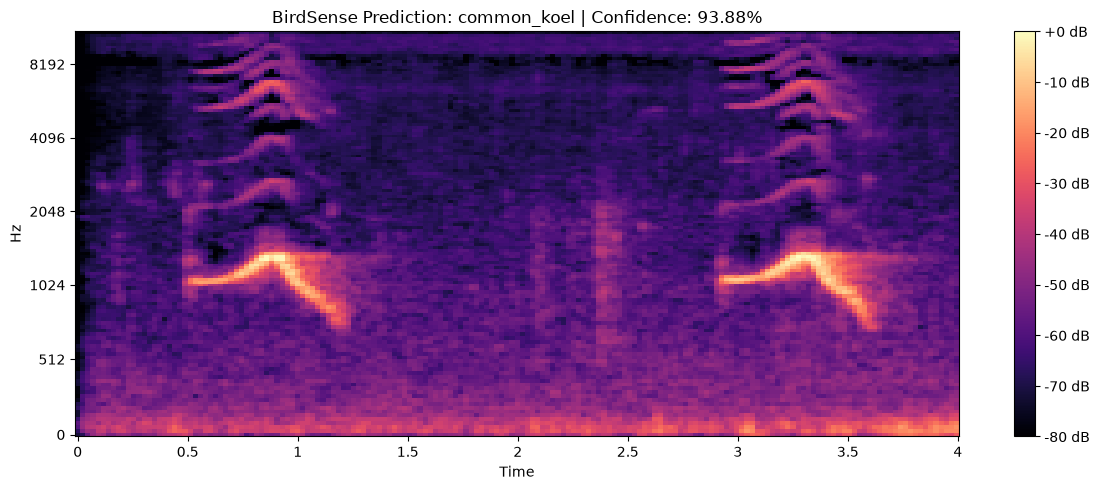

In [138]:
import matplotlib.pyplot as plt
import librosa
import librosa.display

audio, sr = preprocess_audio(test_path)

segment = segment_audio(
    audio,
    sr,
    segment_duration=4
)[0]

mel = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_mels=128
)

mel_db = librosa.power_to_db(mel, ref=np.max)

bird, confidence = predict_bird(test_path)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title(
    f"BirdSense Prediction: {bird} | Confidence: {confidence*100:.2f}%"
)
plt.tight_layout()
plt.show()

In [140]:
print("BirdSense notebook is working.")
print("Classes:", class_names)

BirdSense notebook is working.
Classes: ['common_koel', 'common_myna', 'common_tailorbird', 'greater_coucal', 'house_sparrow', 'indian_robin', 'red_vented_bulbul', 'rose_ringed_parakeet']


In [141]:
print("Classes:", class_names)
print("Test samples:", len(y_test))

Classes: ['common_koel', 'common_myna', 'common_tailorbird', 'greater_coucal', 'house_sparrow', 'indian_robin', 'red_vented_bulbul', 'rose_ringed_parakeet']
Test samples: 65


In [142]:
# Final BirdSense Demo

In [143]:
test_path = audio_files[0]

print("Audio:", test_path.name)

Audio: XC1089796 - Asian Koel - Eudynamys scolopaceus.mp3


In [144]:
bird, confidence = predict_bird(test_path)

print("BirdSense Prediction:", bird)
print("Confidence:", round(confidence * 100, 2), "%")

BirdSense Prediction: common_koel
Confidence: 93.88 %


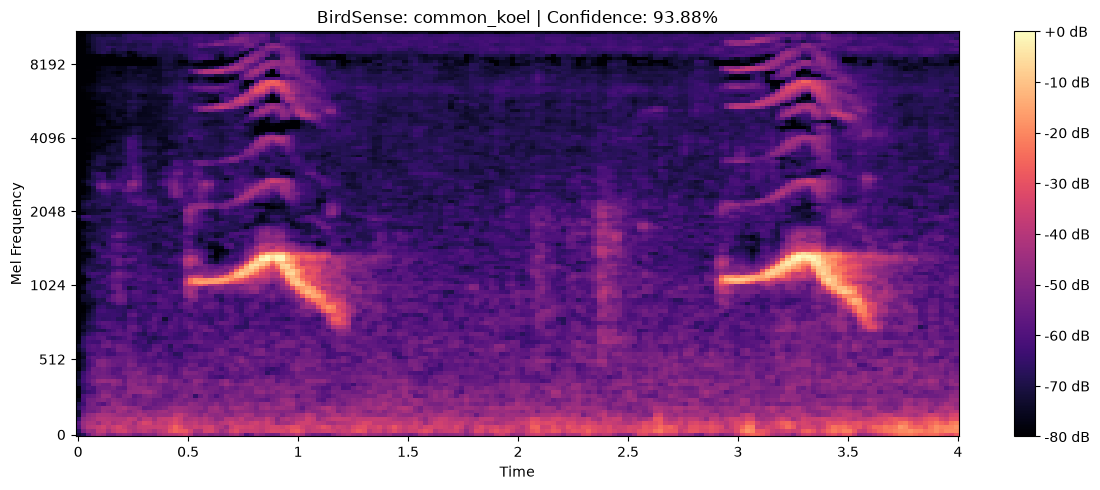

In [145]:
import matplotlib.pyplot as plt
import librosa
import librosa.display

audio, sr = preprocess_audio(test_path)

segment = segment_audio(
    audio,
    sr,
    segment_duration=4
)[0]

mel = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_mels=128
)

mel_db = librosa.power_to_db(mel, ref=np.max)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.xlabel("Time")
plt.ylabel("Mel Frequency")
plt.title(
    f"BirdSense: {bird} | Confidence: {confidence*100:.2f}%"
)
plt.tight_layout()
plt.show()